# Taller práctico de implementación: Unidad 4
## Búsqueda semántica de procedimientos para la atención de incidentes de TI mediante Hugging Face

**Estudiante:** Kevin Alexis Barrera Llerena  
**Programa:** Maestría en Inteligencia Artificial y Ciencia de Datos  
**Asignatura:** Talleres Prácticos de Implementación  
**Universidad:** Casa Grande  
**Entorno:** Python y Google Colab  
**Modelo:** [`intfloat/multilingual-e5-small`](https://huggingface.co/intfloat/multilingual-e5-small)

Este trabajo presenta la implementación y evaluación de un modelo preentrenado de representación semántica de textos para recuperar procedimientos técnicos relacionados con descripciones de incidentes informáticos. El estudio utiliza un catálogo y consultas ficticias elaborados con fines académicos.

## Mapa de cumplimiento de la actividad

| Requisito de la actividad | Dónde se cumple en este notebook |
|---|---|
| Modelo de Hugging Face distinto a los vistos en clase | Sección 2: `intfloat/multilingual-e5-small`, un modelo de *embeddings* para búsqueda semántica. Los notebooks de clase emplean modelos de sentimientos, clasificación, detección de objetos, traducción y generación de texto. |
| Estructura e identificación | Portada con nombre, programa, asignatura y universidad; secciones numeradas del 1 al 17 con introducción, objetivos, desarrollo, conclusiones y referencias. |
| Carga y uso del modelo con pruebas propias | Secciones 6 a 15: catálogo propio de diez procedimientos, carga del modelo, *embeddings*, tres pruebas funcionales, gráfica, evaluación con ocho casos, consulta fuera de dominio y validaciones de entrada. |
| Comentarios e interpretación | Comentarios en todas las celdas de código y apartados de interpretación después de cada resultado; análisis de limitaciones en la sección 16. |
| PDF del notebook ejecutado | Todas las celdas están ejecutadas en orden y sus salidas (tablas y gráfica) son visibles, listas para exportar a PDF. |

## 1. Introducción y objetivos

En la atención de incidentes informáticos, las solicitudes pueden describir un mismo problema con términos diferentes a los empleados en la documentación técnica. La búsqueda semántica permite comparar el significado de los textos y recuperar procedimientos potencialmente relevantes sin depender exclusivamente de coincidencias literales.

**Objetivo general:** implementar y evaluar en Google Colab un modelo de Hugging Face para recuperar procedimientos de diagnóstico a partir de descripciones de incidentes de TI.

**Objetivos específicos:** identificar las características del modelo; estructurar un catálogo de procedimientos; generar representaciones vectoriales de los textos; realizar consultas y visualizar los resultados; evaluar la recuperación mediante Hit@1 y Hit@3; e interpretar sus limitaciones.

La actividad continúa el estudio de aprendizaje automático de la Unidad 3. A diferencia de los clasificadores entrenados en el taller anterior, aquí se aprovecha un modelo lingüístico preentrenado sin realizar un nuevo proceso de entrenamiento. El alcance es experimental y no contempla automatizar acciones sobre sistemas operativos.

## 2. Modelo seleccionado

El modelo empleado es [`intfloat/multilingual-e5-small`](https://huggingface.co/intfloat/multilingual-e5-small), disponible públicamente en Hugging Face. Su tarea consiste en generar representaciones vectoriales (*embeddings*) de textos multilingües, que pueden compararse para establecer relaciones de similitud semántica.

El modelo utiliza una arquitectura basada en Transformer y produce vectores de **384 dimensiones**. En este trabajo se aplica a la recuperación de procedimientos de diagnóstico relacionados con operaciones de TI.

Los materiales prácticos revisados de la unidad incluyen tareas de análisis de sentimientos, clasificación de texto e imágenes, detección de objetos, traducción y generación de contenido. El modelo E5 seleccionado y la aplicación de recuperación semántica de procedimientos no forman parte de los modelos demostrados en los notebooks proporcionados.

Según las indicaciones de su ficha técnica, las consultas se representan con el prefijo `query: ` y los documentos del catálogo con `passage: `. Los valores de similitud resultantes permiten **ordenar** candidatos; no representan probabilidades de diagnóstico acertado.

## 3. Fundamento de la búsqueda semántica

La búsqueda literal depende principalmente de la coincidencia entre palabras. La búsqueda semántica compara las representaciones vectoriales de las frases. Por ejemplo, la consulta «El portal presenta un problema de seguridad porque su certificado caducó» puede relacionarse con un procedimiento titulado «Certificado TLS vencido».

El proceso comprende la codificación del texto con un Transformer, la obtención de su *embedding*, el cálculo de similitudes y el ordenamiento de los procedimientos encontrados.

La similitud coseno entre los vectores de una consulta $q$ y un procedimiento $p$ se expresa como:

$$\operatorname{sim}(q,p)=\frac{q\cdot p}{\lVert q\rVert\,\lVert p\rVert}$$

Cuando los vectores están normalizados, su producto punto equivale a la similitud coseno. Para evaluar la recuperación se emplean las métricas **Hit@1** y **Hit@3**, en lugar de las métricas de clasificación binaria del Taller 3.

## 4. Entorno de ejecución

La implementación se desarrolló en Python, utilizando Google Colab, Hugging Face y la biblioteca `sentence-transformers`. Esta última proporciona una interfaz para cargar el modelo y generar *embeddings*. Se especifican rangos de versiones compatibles de las bibliotecas principales.

Los pesos del modelo son públicos y se obtienen desde Hugging Face cuando no están almacenados en la caché del entorno. Los datos de prueba se definen dentro del propio notebook y no requieren archivos externos.

In [1]:
# Instalación de dependencias (en Colab basta ejecutarla una vez por sesión).
# transformers 4.x es compatible con las versiones de sentence-transformers indicadas.
%pip install -q --disable-pip-version-check "transformers>=4.45,<5" "sentence-transformers>=3.4,<6"

Note: you may need to restart the kernel to use updated packages.


## 5. Importación de bibliotecas y configuración

Se importan las bibliotecas necesarias para la representación vectorial, el tratamiento de datos y la visualización. La semilla aleatoria se establece para favorecer la reproducibilidad de las operaciones que la utilizan. La ejecución puede realizarse en CPU o GPU, según los recursos disponibles.

In [2]:
# Bibliotecas para manejo de datos, cálculo numérico, gráficos y modelos
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
import sentence_transformers
from IPython.display import display
from sentence_transformers import SentenceTransformer

# Semilla fija para favorecer la reproducibilidad
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

# Identificador público del modelo en Hugging Face
MODELO_ID = "intfloat/multilingual-e5-small"

# Se usa GPU si el entorno la ofrece; de lo contrario, CPU (suficiente para este ejercicio)
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"

# Las tablas muestran el texto completo de cada celda para que sean legibles en el PDF
pd.set_option("display.max_colwidth", None)

# Registro del entorno de ejecución
print("Modelo Hugging Face:", MODELO_ID)
print("Dispositivo detectado:", DISPOSITIVO)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Sentence-Transformers:", sentence_transformers.__version__)

Modelo Hugging Face: intfloat/multilingual-e5-small
Dispositivo detectado: cpu
PyTorch: 2.15.0+cpu
Transformers: 4.57.6
Sentence-Transformers: 5.7.0


## 6. Catálogo de procedimientos técnicos

Se construyó un catálogo de **diez procedimientos ficticios** relacionados con incidentes habituales de infraestructura y servicios TI: consumo de CPU, memoria, almacenamiento, errores HTTP, latencia, bases de datos, certificados TLS, DNS, Kubernetes y conectividad.

Cada entrada dispone de un identificador, un título, una descripción y una acción diagnóstica orientativa. Los textos son ejemplos académicos y no corresponden a tickets ni documentación interna de ninguna organización.

In [3]:
# Catálogo académico: cada procedimiento tiene id, título, descripción y acción orientativa.
# Los textos son ficticios y no provienen de ninguna organización.
PROCEDIMIENTOS = [
    {
        "id": "RB-01", "titulo": "Consumo elevado de CPU",
        "descripcion": "Diagnóstico de procesador saturado, procesos con alto consumo y carga de CPU superior al límite esperado.",
        "accion": "Revisar métricas de CPU y procesos activos; documentar el consumo anómalo."
    },
    {
        "id": "RB-02", "titulo": "Memoria RAM agotada",
        "descripcion": "Detección de escasez de memoria, presión de RAM, intercambio swap y procesos finalizados por falta de memoria.",
        "accion": "Consultar memoria disponible, swap y registros de procesos terminados por OOM."
    },
    {
        "id": "RB-03", "titulo": "Espacio en disco insuficiente",
        "descripcion": "Diagnóstico de almacenamiento lleno, particiones sin capacidad, archivos de registro grandes y uso elevado de disco.",
        "accion": "Inspeccionar espacio de particiones y crecimiento de logs antes de cualquier limpieza."
    },
    {
        "id": "RB-04", "titulo": "Errores HTTP 500 y 502",
        "descripcion": "Análisis de errores HTTP 5xx, respuestas 502 Bad Gateway, fallos de proxy y errores de aplicaciones web.",
        "accion": "Revisar registros del proxy, del servicio y trazas de las solicitudes fallidas."
    },
    {
        "id": "RB-05", "titulo": "Latencia elevada en servicios",
        "descripcion": "Investigación de lentitud de aplicaciones, tiempo de respuesta p95 alto y degradación de rendimiento sin caída total.",
        "accion": "Comparar percentiles de latencia y trazas distribuidas por servicio."
    },
    {
        "id": "RB-06", "titulo": "Problemas de conexiones a base de datos",
        "descripcion": "Diagnóstico de consultas SQL lentas, pool de conexiones agotado, bloqueos y fallas de conexión a la base de datos.",
        "accion": "Revisar conexiones activas, bloqueos, consultas y métricas del motor SQL."
    },
    {
        "id": "RB-07", "titulo": "Certificado TLS vencido",
        "descripcion": "Validación de errores HTTPS y SSL, certificados digitales caducados y problemas de cadena de confianza TLS.",
        "accion": "Verificar fechas de validez, emisor y cadena de confianza del certificado."
    },
    {
        "id": "RB-08", "titulo": "Resolución DNS incorrecta",
        "descripcion": "Investigación de nombres de dominio que no resuelven, registros DNS incorrectos y fallas de resolución de nombres.",
        "accion": "Consultar registros DNS y comparar respuestas de resolvedores autorizados."
    },
    {
        "id": "RB-09", "titulo": "Reinicios de contenedores Kubernetes",
        "descripcion": "Diagnóstico de pods Kubernetes que reinician, estado CrashLoopBackOff y errores de inicialización de contenedores.",
        "accion": "Inspeccionar eventos del pod, estado de los contenedores y registros de inicio."
    },
    {
        "id": "RB-10", "titulo": "Pérdida de paquetes de red",
        "descripcion": "Análisis de cortes intermitentes, pérdida de paquetes, timeouts de red e inestabilidad de conectividad.",
        "accion": "Contrastar pérdida de paquetes, saltos de red y métricas de enlaces."
    },
]

# Verificaciones de integridad: 10 entradas, identificadores únicos y textos no vacíos
assert len(PROCEDIMIENTOS) == 10
assert len({p["id"] for p in PROCEDIMIENTOS}) == len(PROCEDIMIENTOS)
assert all(p["titulo"].strip() and p["descripcion"].strip() for p in PROCEDIMIENTOS)

# Tabla con el catálogo para visualizarlo
catalogo = pd.DataFrame(PROCEDIMIENTOS)
print("Procedimientos académicos disponibles:", len(catalogo))
display(catalogo[["id", "titulo", "descripcion"]])

Procedimientos académicos disponibles: 10


,id,titulo,descripcion
0,RB-01,Consumo elevado de CPU,"Diagnóstico de procesador saturado, procesos con alto consumo y carga de CPU superior al límite esperado."
1,RB-02,Memoria RAM agotada,"Detección de escasez de memoria, presión de RAM, intercambio swap y procesos finalizados por falta de memoria."
2,RB-03,Espacio en disco insuficiente,"Diagnóstico de almacenamiento lleno, particiones sin capacidad, archivos de registro grandes y uso elevado de disco."
3,RB-04,Errores HTTP 500 y 502,"Análisis de errores HTTP 5xx, respuestas 502 Bad Gateway, fallos de proxy y errores de aplicaciones web."
4,RB-05,Latencia elevada en servicios,"Investigación de lentitud de aplicaciones, tiempo de respuesta p95 alto y degradación de rendimiento sin caída total."
5,RB-06,Problemas de conexiones a base de datos,"Diagnóstico de consultas SQL lentas, pool de conexiones agotado, bloqueos y fallas de conexión a la base de datos."
6,RB-07,Certificado TLS vencido,"Validación de errores HTTPS y SSL, certificados digitales caducados y problemas de cadena de confianza TLS."
7,RB-08,Resolución DNS incorrecta,"Investigación de nombres de dominio que no resuelven, registros DNS incorrectos y fallas de resolución de nombres."
8,RB-09,Reinicios de contenedores Kubernetes,"Diagnóstico de pods Kubernetes que reinician, estado CrashLoopBackOff y errores de inicialización de contenedores."
9,RB-10,Pérdida de paquetes de red,"Análisis de cortes intermitentes, pérdida de paquetes, timeouts de red e inestabilidad de conectividad."


## 7. Carga del modelo preentrenado

El modelo se carga mediante `SentenceTransformer`, indicando su identificador público y el dispositivo disponible. Se comprueba la dimensión de los vectores generados. Los parámetros del modelo permanecen sin ajustes adicionales: no se realiza entrenamiento ni ajuste fino (*fine-tuning*).

In [4]:
# Carga del modelo preentrenado desde Hugging Face (se descarga la primera vez)
modelo = SentenceTransformer(MODELO_ID, device=DISPOSITIVO)

# Dimensión de los vectores; el nombre del método depende de la versión de la biblioteca
dimension = (modelo.get_embedding_dimension() if hasattr(modelo, "get_embedding_dimension")
             else modelo.get_sentence_embedding_dimension())

print("Modelo cargado:", MODELO_ID)
print("Dimensión del embedding:", dimension)

# Comprobación: la ficha del modelo indica vectores de 384 dimensiones
assert dimension == 384, "Dimensión distinta a la indicada en la ficha del modelo."

Modelo cargado: intfloat/multilingual-e5-small
Dimensión del embedding: 384


## 8. Representación vectorial del catálogo

Cada procedimiento se transforma en un texto precedido por `passage: `. Posteriormente, `encode()` genera y normaliza las representaciones vectoriales. La matriz resultante tiene diez filas, correspondientes a los procedimientos, y 384 columnas, correspondientes a las dimensiones de los *embeddings*.

Esta matriz se conserva en memoria para reutilizarla durante las consultas.

In [5]:
# Texto de cada procedimiento: prefijo "passage: " (exigido por E5 para documentos) + título + descripción
textos_catalogo = [
    f"passage: {p['titulo']}. {p['descripcion']}"
    for p in PROCEDIMIENTOS
]

# Conversión de los textos en vectores. Con normalize_embeddings=True cada vector queda con norma 1,
# por lo que el producto punto entre dos vectores equivale a su similitud coseno.
embeddings_catalogo = modelo.encode(
    textos_catalogo,
    batch_size=8,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=False,
)

# Comprobaciones: matriz de 10 filas x 384 columnas y valores numéricos válidos
assert embeddings_catalogo.shape == (len(PROCEDIMIENTOS), dimension)
assert np.isfinite(embeddings_catalogo).all()
print("Forma de la matriz de embeddings:", embeddings_catalogo.shape)
print("Se indexaron", len(PROCEDIMIENTOS), "procedimientos en memoria.")

Forma de la matriz de embeddings: (10, 384)
Se indexaron 10 procedimientos en memoria.


## 9. Recuperación y ordenamiento de procedimientos

La función `buscar_procedimientos()` valida la consulta y la cantidad de resultados solicitados. Después genera el *embedding* del texto precedido por `query: `, calcula la similitud con cada procedimiento y presenta los candidatos ordenados de mayor a menor.

La salida incluye el identificador, el título, la similitud coseno y una acción diagnóstica orientativa. La posición obtenida representa relevancia relativa dentro del catálogo, no certeza sobre la causa del incidente.

In [6]:
def buscar_procedimientos(consulta: str, top_k: int = 3) -> pd.DataFrame:
    """Recupera los procedimientos con mayor similitud semántica para una consulta."""
    # Validación de entradas: consulta no vacía y top_k dentro del tamaño del catálogo
    if not isinstance(consulta, str) or not consulta.strip():
        raise ValueError("La consulta debe ser un texto no vacío.")
    if not isinstance(top_k, int) or not 1 <= top_k <= len(PROCEDIMIENTOS):
        raise ValueError(f"top_k debe estar entre 1 y {len(PROCEDIMIENTOS)}.")

    # Embedding de la consulta con el prefijo "query: " que exige el modelo E5
    embedding_consulta = modelo.encode(
        "query: " + consulta.strip(),
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=False,
    )

    # Similitud coseno con los 10 procedimientos (producto punto de vectores normalizados)
    similitudes = embeddings_catalogo @ embedding_consulta

    # Posiciones de los k mayores valores, de mayor a menor similitud
    posiciones = np.argsort(-similitudes, kind="stable")[:top_k]

    # Se arma la tabla de resultados con posición, código, título, similitud y acción orientativa
    resultados = []
    for puesto, idx in enumerate(posiciones, start=1):
        procedimiento = PROCEDIMIENTOS[int(idx)]
        resultados.append({
            "Posición": puesto,
            "Código": procedimiento["id"],
            "Procedimiento": procedimiento["titulo"],
            "Similitud coseno": round(float(similitudes[idx]), 4),
            "Acción orientativa": procedimiento["accion"],
        })
    return pd.DataFrame(resultados)

print("Función de recuperación semántica definida correctamente.")

Función de recuperación semántica definida correctamente.


## 10. Pruebas funcionales

Se emplean tres consultas elaboradas para el ejercicio. Los escenarios describen la caducidad de un certificado, el reinicio repetido de contenedores y un problema de resolución de nombres. Para cada consulta se presentan los tres procedimientos mejor posicionados, lo que permite comparar la descripción de entrada con el resultado recuperado.

In [7]:
# Tres consultas propias, redactadas sin copiar el texto exacto del catálogo
CONSULTAS_DEMOSTRACION = [
    "El sistema rechaza conexiones seguras porque venció el certificado del portal.",
    "Los contenedores de la aplicación se reinician una y otra vez al iniciar.",
    "Los usuarios no pueden consultar el dominio del servicio desde ciertas redes.",
]

# Para cada consulta se muestran los tres procedimientos con mayor similitud
for indice, consulta in enumerate(CONSULTAS_DEMOSTRACION, start=1):
    print(f"\nPRUEBA FUNCIONAL {indice}")
    print("Entrada:", consulta)
    display(buscar_procedimientos(consulta, top_k=3))


PRUEBA FUNCIONAL 1
Entrada: El sistema rechaza conexiones seguras porque venció el certificado del portal.


,Posición,Código,Procedimiento,Similitud coseno,Acción orientativa
0,1,RB-07,Certificado TLS vencido,0.8583,"Verificar fechas de validez, emisor y cadena de confianza del certificado."
1,2,RB-10,Pérdida de paquetes de red,0.8326,"Contrastar pérdida de paquetes, saltos de red y métricas de enlaces."
2,3,RB-06,Problemas de conexiones a base de datos,0.8302,"Revisar conexiones activas, bloqueos, consultas y métricas del motor SQL."



PRUEBA FUNCIONAL 2
Entrada: Los contenedores de la aplicación se reinician una y otra vez al iniciar.


,Posición,Código,Procedimiento,Similitud coseno,Acción orientativa
0,1,RB-09,Reinicios de contenedores Kubernetes,0.8932,"Inspeccionar eventos del pod, estado de los contenedores y registros de inicio."
1,2,RB-10,Pérdida de paquetes de red,0.8295,"Contrastar pérdida de paquetes, saltos de red y métricas de enlaces."
2,3,RB-04,Errores HTTP 500 y 502,0.8253,"Revisar registros del proxy, del servicio y trazas de las solicitudes fallidas."



PRUEBA FUNCIONAL 3
Entrada: Los usuarios no pueden consultar el dominio del servicio desde ciertas redes.


,Posición,Código,Procedimiento,Similitud coseno,Acción orientativa
0,1,RB-08,Resolución DNS incorrecta,0.8545,Consultar registros DNS y comparar respuestas de resolvedores autorizados.
1,2,RB-10,Pérdida de paquetes de red,0.8478,"Contrastar pérdida de paquetes, saltos de red y métricas de enlaces."
2,3,RB-04,Errores HTTP 500 y 502,0.8427,"Revisar registros del proxy, del servicio y trazas de las solicitudes fallidas."


### Interpretación de las pruebas funcionales

En las tres consultas el primer resultado fue el procedimiento esperado: el certificado vencido recuperó RB-07, los contenedores que se reinician recuperaron RB-09 y el dominio inaccesible recuperó RB-08. Ninguna consulta repite el título del procedimiento; por ejemplo, «venció el certificado del portal» se asocia con «Certificado TLS vencido» por su significado y no por una coincidencia exacta de palabras.

También se observa que RB-10 (Pérdida de paquetes de red) ocupó el segundo lugar en las tres pruebas. En la tercera consulta su similitud (0,8478) quedó muy cerca de la del primer resultado (0,8545). Por eso el orden debe leerse como una prioridad de revisión y no como una certeza: los lugares segundo y tercero no son necesariamente pertinentes.

## 11. Visualización de resultados

Para una consulta sobre un error HTTP 502 se representan gráficamente los cinco procedimientos con mayor similitud. La visualización permite reconocer diferencias en la puntuación de los candidatos, sin interpretar el valor numérico como una probabilidad de éxito de las acciones propuestas.

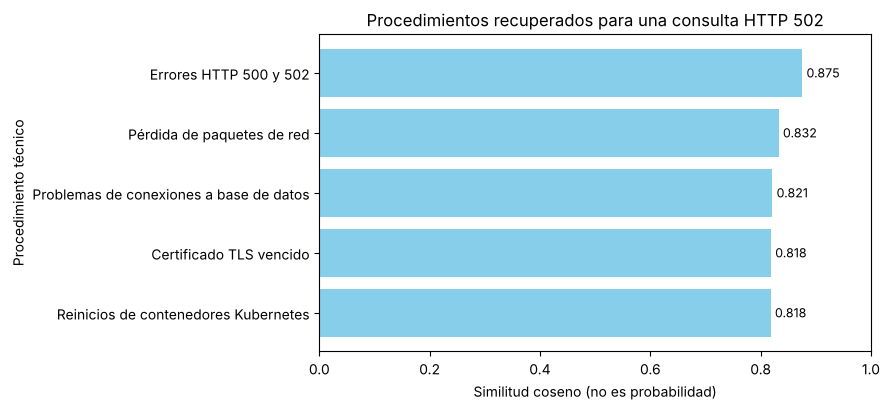

Consulta graficada: La API devuelve error 502 al acceder desde el navegador.


In [8]:
# Consulta de ejemplo y los cinco procedimientos más cercanos
consulta_grafico = "La API devuelve error 502 al acceder desde el navegador."
resultado_grafico = buscar_procedimientos(consulta_grafico, top_k=5)

# Se invierte el orden para que el mejor resultado quede arriba en el gráfico de barras horizontales
grafico = resultado_grafico.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.2))
barras = ax.barh(grafico["Procedimiento"], grafico["Similitud coseno"], color="skyblue")
ax.set_title("Procedimientos recuperados para una consulta HTTP 502")
ax.set_xlabel("Similitud coseno (no es probabilidad)")
ax.set_ylabel("Procedimiento técnico")
ax.set_xlim(min(0, float(grafico["Similitud coseno"].min()) - 0.05), 1.0)

# Valor numérico de la similitud al final de cada barra
for barra, valor in zip(barras, grafico["Similitud coseno"]):
    ax.text(float(barra.get_width()) + 0.008, barra.get_y() + barra.get_height() / 2,
            f"{float(valor):.3f}", va="center", fontsize=9)
fig.tight_layout()
plt.show()
print("Consulta graficada:", consulta_grafico)

### Interpretación de la gráfica

Para la consulta sobre el error 502, el procedimiento «Errores HTTP 500 y 502» obtuvo la mayor similitud (0,875), seguido por «Pérdida de paquetes de red» (0,832). Los tres últimos candidatos tienen valores casi iguales, entre 0,818 y 0,821. Las barras parten de cero para no exagerar las diferencias; como todos los valores quedan en un intervalo estrecho, lo informativo es el orden y la distancia entre posiciones, no el valor absoluto de la similitud.

## 12. Diseño de la evaluación

Se definieron ocho incidentes ficticios, cada uno asociado manualmente con el procedimiento considerado pertinente. Este conjunto permite realizar una comprobación funcional del comportamiento del recuperador, aunque su tamaño y elaboración didáctica impiden generalizar los resultados a entornos de producción.

**Hit@1:** proporción de consultas cuyo procedimiento esperado aparece en la primera posición.

**Hit@3:** proporción de consultas cuyo procedimiento esperado aparece entre los tres primeros resultados.

Ambas métricas se calculan comparando las posiciones obtenidas con los identificadores previamente establecidos.

In [9]:
# Ocho incidentes ficticios con el procedimiento esperado asignado manualmente
CASOS_EVALUACION = [
    {"caso": "T01", "consulta": "El servidor se quedó sin espacio para escribir archivos de log.", "esperado": "RB-03"},
    {"caso": "T02", "consulta": "Al entrar a la web aparece 502 Bad Gateway.", "esperado": "RB-04"},
    {"caso": "T03", "consulta": "El dominio no resuelve y los clientes no encuentran el sitio.", "esperado": "RB-08"},
    {"caso": "T04", "consulta": "La página HTTPS advierte que el certificado digital ha caducado.", "esperado": "RB-07"},
    {"caso": "T05", "consulta": "Un pod de Kubernetes queda en CrashLoopBackOff.", "esperado": "RB-09"},
    {"caso": "T06", "consulta": "El sistema operativo termina aplicaciones porque la memoria está llena.", "esperado": "RB-02"},
    {"caso": "T07", "consulta": "La base de datos está lenta y no quedan conexiones disponibles.", "esperado": "RB-06"},
    {"caso": "T08", "consulta": "El servidor tiene CPU muy alta y varios procesos al máximo.", "esperado": "RB-01"},
]

# Verificaciones: los códigos esperados existen en el catálogo y hay casos suficientes
ids_validos = {item["id"] for item in PROCEDIMIENTOS}
assert all(caso["esperado"] in ids_validos for caso in CASOS_EVALUACION)
assert len(CASOS_EVALUACION) >= 3

# Se ejecuta la búsqueda de cada caso y se registra si el esperado quedó en el Top 1 y en el Top 3
filas_evaluacion = []
for caso in CASOS_EVALUACION:
    resultados = buscar_procedimientos(caso["consulta"], top_k=3)
    encontrados = resultados["Código"].tolist()
    filas_evaluacion.append({
        "Caso": caso["caso"],
        "Incidente ficticio": caso["consulta"],
        "Esperado": caso["esperado"],
        "Top 1": encontrados[0],
        "Top 3": ", ".join(encontrados),
        "Similitud Top 1": float(resultados["Similitud coseno"].iloc[0]),
        # Hit@1 = 1 si el esperado es el primero; Hit@3 = 1 si está entre los tres primeros
        "Hit@1": int(caso["esperado"] == encontrados[0]),
        "Hit@3": int(caso["esperado"] in encontrados),
    })

# Tabla final de la evaluación
evaluacion = pd.DataFrame(filas_evaluacion)
display(evaluacion)

,Caso,Incidente ficticio,Esperado,Top 1,Top 3,Similitud Top 1,Hit@1,Hit@3
0,T01,El servidor se quedó sin espacio para escribir archivos de log.,RB-03,RB-03,"RB-03, RB-10, RB-02",0.8619,1,1
1,T02,Al entrar a la web aparece 502 Bad Gateway.,RB-04,RB-04,"RB-04, RB-10, RB-06",0.8966,1,1
2,T03,El dominio no resuelve y los clientes no encuentran el sitio.,RB-08,RB-08,"RB-08, RB-10, RB-04",0.8633,1,1
3,T04,La página HTTPS advierte que el certificado digital ha caducado.,RB-07,RB-07,"RB-07, RB-10, RB-04",0.8891,1,1
4,T05,Un pod de Kubernetes queda en CrashLoopBackOff.,RB-09,RB-09,"RB-09, RB-10, RB-06",0.8963,1,1
5,T06,El sistema operativo termina aplicaciones porque la memoria está llena.,RB-02,RB-02,"RB-02, RB-03, RB-05",0.8697,1,1
6,T07,La base de datos está lenta y no quedan conexiones disponibles.,RB-06,RB-06,"RB-06, RB-03, RB-10",0.9055,1,1
7,T08,El servidor tiene CPU muy alta y varios procesos al máximo.,RB-01,RB-01,"RB-01, RB-05, RB-03",0.8709,1,1


### Lectura de la tabla de evaluación

En los ocho casos la columna «Top 1» coincide con la columna «Esperado», por lo que Hit@1 vale 1 en todas las filas y, en consecuencia, Hit@3 también. La similitud del primer resultado estuvo entre 0,8619 y 0,9055. Las consultas se redactaron con frases propias, distintas a las del catálogo.

## 13. Resultados de la evaluación

La siguiente sección calcula Hit@1 y Hit@3 a partir de los ocho casos. Los indicadores reflejan el grado de coincidencia con las referencias asignadas manualmente para el ejercicio.

Un resultado alto en esta prueba limitada no implica que el modelo identifique correctamente la causa raíz de incidentes reales; solo evidencia su comportamiento ante las consultas y el catálogo utilizados.

In [10]:
# Conteo de aciertos y cálculo de las métricas: aciertos / total de casos
exitos_top1 = int(evaluacion["Hit@1"].sum())
exitos_top3 = int(evaluacion["Hit@3"].sum())
total_casos = len(evaluacion)
hit1 = exitos_top1 / total_casos
hit3 = exitos_top3 / total_casos

# Tabla resumen de métricas
resumen_metricas = pd.DataFrame([
    {"Métrica": "Hit@1", "Aciertos": exitos_top1, "Total": total_casos, "Resultado": f"{hit1:.1%}"},
    {"Métrica": "Hit@3", "Aciertos": exitos_top3, "Total": total_casos, "Resultado": f"{hit3:.1%}"},
])
print("Resultados obtenidos en esta ejecución:")
display(resumen_metricas)

# Interpretación automática según los valores obtenidos en esta ejecución
if hit1 == 1.0:
    print("Interpretación: el procedimiento esperado fue el primero en los ocho casos del ejercicio.")
else:
    print(f"Interpretación: {total_casos - exitos_top1} caso(s) no colocaron el procedimiento esperado en primer lugar.")
if hit3 == 1.0:
    print("El procedimiento esperado apareció entre los tres primeros en todos los casos.")
else:
    print(f"En {total_casos - exitos_top3} caso(s) el procedimiento esperado no apareció entre los tres primeros.")

# Casos cuyo procedimiento esperado no quedó en primer lugar (si los hubiera)
fallos = evaluacion.loc[evaluacion["Hit@1"] == 0, ["Caso", "Esperado", "Top 1", "Top 3"]]
if len(fallos):
    print("Casos que requieren revisión humana:")
    display(fallos)
else:
    print("No se observaron discrepancias Top 1 en estos casos académicos.")

Resultados obtenidos en esta ejecución:


,Métrica,Aciertos,Total,Resultado
0,Hit@1,8,8,100.0%
1,Hit@3,8,8,100.0%


Interpretación: el procedimiento esperado fue el primero en los ocho casos del ejercicio.
El procedimiento esperado apareció entre los tres primeros en todos los casos.
No se observaron discrepancias Top 1 en estos casos académicos.


### Interpretación de Hit@1 y Hit@3

- **Hit@1 = 8/8 = 100 %:** en todos los casos el procedimiento esperado fue el primer resultado.
- **Hit@3 = 8/8 = 100 %:** en todos los casos el esperado estuvo entre los tres primeros. Como Hit@1 ya es perfecto, Hit@3 no aporta información adicional en esta ejecución.

Para dimensionar estos valores, un orden al azar sobre diez procedimientos daría en promedio Hit@1 = 10 % y Hit@3 = 30 %. El resultado supera ampliamente esa referencia, pero proviene de una prueba pequeña: ocho consultas redactadas para el ejercicio y un catálogo de categorías bien diferenciadas. A diferencia de Accuracy o F1 del Taller 3, estas métricas evalúan la posición en un ranking, no una clase predicha.

## 14. Comportamiento ante consultas ajenas al dominio

También se evalúa una consulta sobre un tema no relacionado con incidentes de TI. El buscador devuelve resultados porque su función consiste en ordenar los documentos disponibles, incluso cuando ninguno es pertinente.

Esta prueba pone de manifiesto que las puntuaciones de similitud no deben utilizarse como una probabilidad de respuesta correcta. Una implementación operativa necesitaría criterios de rechazo de consultas fuera de dominio y revisión de la pertinencia de las recomendaciones.

In [11]:
# Consulta sin relación con TI (impuestos): ningún procedimiento del catálogo es pertinente
consulta_fuera_de_dominio = "Quiero saber cómo calcular el impuesto al valor agregado de una compra."
print("Consulta ajena al catálogo:", consulta_fuera_de_dominio)

# El buscador igualmente devuelve un ranking, porque solo ordena los documentos disponibles
display(buscar_procedimientos(consulta_fuera_de_dominio, top_k=3))
print("Advertencia: siempre aparece un ranking, aunque ningún procedimiento sea pertinente.")

Consulta ajena al catálogo: Quiero saber cómo calcular el impuesto al valor agregado de una compra.


,Posición,Código,Procedimiento,Similitud coseno,Acción orientativa
0,1,RB-01,Consumo elevado de CPU,0.8029,Revisar métricas de CPU y procesos activos; documentar el consumo anómalo.
1,2,RB-10,Pérdida de paquetes de red,0.8011,"Contrastar pérdida de paquetes, saltos de red y métricas de enlaces."
2,3,RB-03,Espacio en disco insuficiente,0.8004,Inspeccionar espacio de particiones y crecimiento de logs antes de cualquier limpieza.


Advertencia: siempre aparece un ranking, aunque ningún procedimiento sea pertinente.


### Análisis complementario de los puntajes

La siguiente celda compara los puntajes de las consultas de TI con los de la consulta fuera de dominio, mide la separación entre el primer y el segundo resultado, y cuenta cuántas veces aparece cada procedimiento en el Top 3.

In [12]:
# Análisis complementario de los puntajes de similitud

# 1) Similitud del Top 1 en los casos de TI frente a la consulta fuera de dominio
sim_ti = evaluacion["Similitud Top 1"]
sim_fuera = buscar_procedimientos(consulta_fuera_de_dominio, top_k=1)["Similitud coseno"].iloc[0]
print(f"Top 1 en los {len(sim_ti)} casos de TI: mínimo {sim_ti.min():.4f}, máximo {sim_ti.max():.4f}")
print(f"Top 1 en la consulta fuera de dominio: {sim_fuera:.4f}")

# 2) Margen = similitud del primer resultado menos la del segundo
def margen(consulta):
    r = buscar_procedimientos(consulta, top_k=2)["Similitud coseno"]
    return float(r.iloc[0] - r.iloc[1])

margenes_ti = [margen(caso["consulta"]) for caso in CASOS_EVALUACION]
print(f"Margen Top 1 - Top 2 en casos de TI: mínimo {min(margenes_ti):.4f}, máximo {max(margenes_ti):.4f}")
print(f"Margen Top 1 - Top 2 fuera de dominio: {margen(consulta_fuera_de_dominio):.4f}")

# 3) Número de apariciones de cada procedimiento en el Top 3 de los ocho casos
frecuencia = (evaluacion["Top 3"].str.split(", ").explode().value_counts()
              .rename_axis("Código").reset_index(name="Apariciones en Top 3"))
display(frecuencia)

# 4) Procedimientos que no son la respuesta esperada de ningún caso de evaluación
sin_caso = sorted(ids_validos - set(evaluacion["Esperado"]))
print("Procedimientos sin caso de evaluación propio:", sin_caso)

Top 1 en los 8 casos de TI: mínimo 0.8619, máximo 0.9055
Top 1 en la consulta fuera de dominio: 0.8029
Margen Top 1 - Top 2 en casos de TI: mínimo 0.0081, máximo 0.0509


Margen Top 1 - Top 2 fuera de dominio: 0.0018


,Código,Apariciones en Top 3
0,RB-10,6
1,RB-03,4
2,RB-04,3
3,RB-06,3
4,RB-02,2
5,RB-05,2
6,RB-08,1
7,RB-07,1
8,RB-09,1
9,RB-01,1


Procedimientos sin caso de evaluación propio: ['RB-05', 'RB-10']


### Interpretación del análisis de puntajes

- **Fuera de dominio:** la consulta sobre impuestos obtuvo un Top 1 de 0,8029, inferior al mínimo de los casos de TI (0,8619). En esta muestra un umbral entre ambos valores separaría los dos grupos, pero se probó una sola consulta ajena al dominio, por lo que no es posible fijar un umbral confiable con esta evidencia.
- **Margen entre posiciones:** en los casos de TI la diferencia entre el primer y el segundo resultado fue de 0,0081 a 0,0509; fuera de dominio fue de solo 0,0018, es decir, el buscador no distingue claramente un candidato mejor. Aun así, el margen mínimo de los casos de TI también es pequeño, lo que confirma que los puntajes ocupan un intervalo estrecho y que sus diferencias absolutas no son fáciles de interpretar.
- **Procedimiento recurrente:** RB-10 apareció en el Top 3 de 6 de los 8 casos sin ser el esperado en ninguno. Su descripción es genérica (cortes, timeouts, conectividad) y se parece a muchas consultas. Esto vuelve menos exigente a Hit@3.
- **Cobertura de la evaluación:** RB-05 y RB-10 no son la respuesta esperada de ningún caso, de modo que su recuperación correcta no se comprobó.


## 15. Validaciones de entrada

Se comprueba que la función rechace consultas vacías y cantidades de resultados fuera de los límites admitidos. Además, se valida que la búsqueda entregue el número solicitado de procedimientos y respete el orden descendente de similitud. Estas verificaciones evalúan la robustez básica de la implementación, no la calidad semántica del modelo.

In [13]:
# Entradas inválidas: consulta vacía, solo espacios, top_k = 0 y top_k mayor al tamaño del catálogo
for consulta_invalida, k_invalido in [("", 3), ("   ", 3), ("Prueba", 0), ("Prueba", 99)]:
    try:
        buscar_procedimientos(consulta_invalida, top_k=k_invalido)
        raise AssertionError("Debió rechazarse una entrada inválida.")
    except ValueError:
        pass  # Comportamiento esperado: la función rechaza la entrada

# Entrada válida: devuelve exactamente 2 resultados y en orden descendente de similitud
resultado_valido = buscar_procedimientos("error DNS", top_k=2)
assert len(resultado_valido) == 2
assert resultado_valido["Similitud coseno"].is_monotonic_decreasing
print("Controles de entrada y orden de resultados: correctos.")

Controles de entrada y orden de resultados: correctos.


## 16. Discusión y conclusiones

La implementación permitió cargar el modelo `intfloat/multilingual-e5-small` y representar un catálogo de diez procedimientos mediante vectores de 384 dimensiones. En las tres demostraciones, el procedimiento correspondiente al problema descrito apareció en la primera posición. La evaluación adicional registró **8 aciertos en 8 casos para Hit@1 y Hit@3**, equivalentes al 100 % en este conjunto de prueba.

Estos resultados confirman el funcionamiento del procedimiento de recuperación en los escenarios definidos, pero no constituyen una medida de precisión generalizable. Las consultas y sus respuestas esperadas fueron elaboradas para un catálogo pequeño y de categorías bien diferenciadas. Sería necesario ampliar y diversificar los datos para evaluar situaciones ambiguas, consultas incompletas y procedimientos con descripciones semejantes.

La consulta ajena al dominio también produjo una lista ordenada de procedimientos, a pesar de no existir una respuesta técnicamente adecuada. Esto evidencia una limitación importante: **la similitud semántica no equivale a la verificación de una solución**. En un sistema real serían indispensables la validación humana, el control de acceso a la documentación, las pruebas con incidentes históricos autorizados y los mecanismos para abstenerse de recomendar información irrelevante.

Otras limitaciones observadas en esta ejecución: el procedimiento RB-10 apareció en el Top 3 de seis de los ocho casos sin ser el esperado, lo que hace menos exigente la métrica Hit@3; además, RB-05 y RB-10 no tienen un caso de evaluación propio. Como trabajo posterior se podrían agregar casos ambiguos y consultas con errores de redacción, y definir un criterio de abstención para consultas fuera de dominio, validado con más ejemplos.

El principal aprendizaje del taller fue aplicar un Transformer preentrenado a una tarea de recuperación de información, comprender la generación y comparación de *embeddings* y utilizar métricas de evaluación adecuadas al objetivo. A diferencia del taller anterior, no fue necesario entrenar un clasificador; el trabajo se centró en la aplicación e interpretación del modelo disponible en Hugging Face.

## 17. Referencias

1. Hugging Face. (s. f.). *intfloat/multilingual-e5-small*. https://huggingface.co/intfloat/multilingual-e5-small
2. Wang, L. et al. (2024). *Multilingual E5 Text Embeddings: A Technical Report*. https://arxiv.org/abs/2402.05672
3. Sentence Transformers. (s. f.). *Semantic Search*. https://www.sbert.net/examples/sentence_transformer/applications/semantic-search/README.html
4. Universidad Casa Grande. (2026). *Taller práctico de implementación: Unidad 4*. Material de clase y guía de actividades del aula virtual.